In [1]:
# a. Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Input

In [2]:
# a. Loading and preprocessing image data

# Load training and testing CSV files
train_data = pd.read_csv(r"D:\Downloads\DL DATASET\Fashion MNIST\fashion-mnist_train.csv")
test_data = pd.read_csv(r"D:\Downloads\DL DATASET\Fashion MNIST\fashion-mnist_test.csv")


In [3]:
# Check dataset shapes
print("Training Dataset Shape:", train_data.shape)
print("Testing Dataset Shape:", test_data.shape)

# Separate images and labels
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

Training Dataset Shape: (60000, 785)
Testing Dataset Shape: (10000, 785)


In [4]:
# Normalize pixel values
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0


In [5]:
# Reshape images into 28x28 grayscale images
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (60000, 28, 28, 1)
X_test shape: (10000, 28, 28, 1)


In [6]:
# Fashion MNIST class names
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

In [7]:
model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

In [8]:
# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

In [9]:
# c. Training the model
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 74s 84ms/step - accuracy: 0.8140 - loss: 0.5160 - val_accuracy: 0.8708 - val_loss: 0.3695
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 89s 95ms/step - accuracy: 0.8750 - loss: 0.3443 - val_accuracy: 0.8860 - val_loss: 0.3177
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 70s 94ms/step - accuracy: 0.8935 - loss: 0.2938 - val_accuracy: 0.8970 - val_loss: 0.2932
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 95ms/step - accuracy: 0.9021 - loss: 0.2647 - val_accuracy: 0.9010 - val_loss: 0.2721
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 66s 88ms/step - accuracy: 0.9115 - loss: 0.2394 - val_accuracy: 0.8977 - val_loss: 0.2750
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 93s 103ms/step - accuracy: 0.9205 - loss: 0.2153 - val_accuracy: 0.9075 - val_loss: 0.2546
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 73s 96ms/step - accuracy: 0.9264 - loss: 0.1983 - val_accuracy: 0.9129 - val_loss: 0.2433
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 108ms/step - accuracy: 0.9352 - loss: 0.1764 

In [10]:

# d. Estimating model performance
loss, accuracy = model.evaluate(X_test, y_test)

print("\nTest Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.9175 - loss: 0.2363

Test Loss: 0.2362777143716812
Test Accuracy: 0.9175000190734863


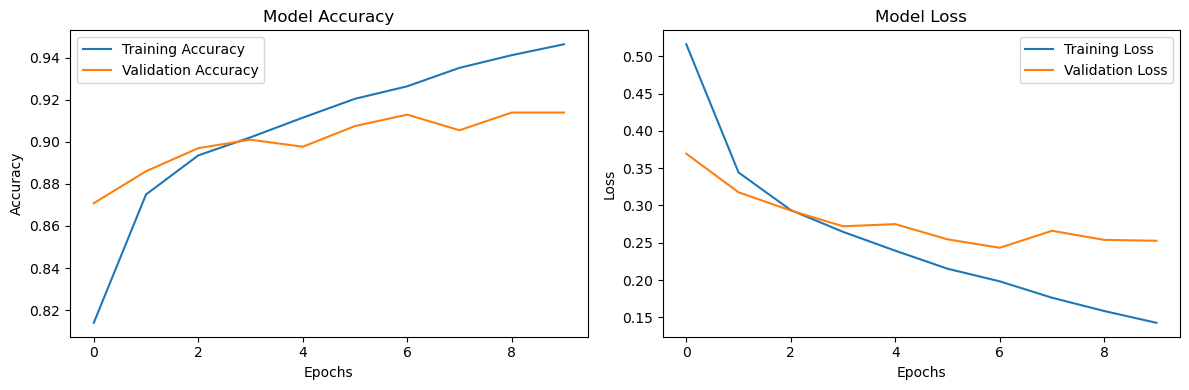

In [11]:
# Plot training and validation accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 580ms/step


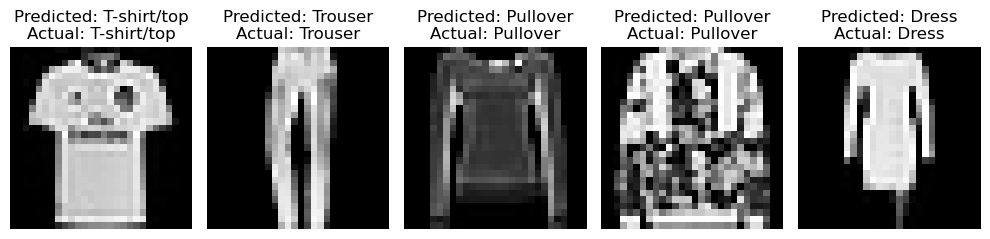

In [12]:
# Display sample predictions
predictions = model.predict(X_test[:5])
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title(
        f"Predicted: {class_names[predicted_labels[i]]}\n"
        f"Actual: {class_names[y_test[i]]}"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()
